In [165]:
# ============================================================
#  TASK 1 - NETFLIX DATA CLEANING & PREPARATION
# ============================================================

In [166]:
import pandas as pd

In [167]:
df=pd.read_csv('Dataset.csv')

In [168]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [169]:
df.shape

(8790, 10)

In [170]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 686.8 KB


In [171]:
df.isnull().sum()

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

In [172]:
df.duplicated().sum()

np.int64(0)

In [173]:
cleaned_df=df.copy()

In [174]:
cleaned_df=cleaned_df.drop_duplicates()

In [175]:
cleaned_df["type"].unique()

<StringArray>
['Movie', 'TV Show']
Length: 2, dtype: str

In [176]:
cleaned_df["rating"].unique()

<StringArray>
[   'PG-13',    'TV-MA',    'TV-PG',    'TV-14',    'TV-Y7',     'TV-Y',
       'PG',     'TV-G',        'R',        'G',    'NC-17',       'NR',
 'TV-Y7-FV',       'UR']
Length: 14, dtype: str

In [177]:
cleaned_df["type"]=cleaned_df["type"].str.strip().str.title()

In [178]:
cleaned_df["rating"]=cleaned_df["rating"].str.strip().str.title()

In [179]:
cleaned_df["country"]=cleaned_df["country"].str.strip()

In [180]:
cleaned_df.isnull().sum()

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

In [181]:
cleaned_df.duplicated().sum()

np.int64(0)

In [182]:
cleaned_df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,Pg-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,Tv-Ma,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,Tv-Ma,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,Tv-Pg,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,Tv-Ma,125 min,"Dramas, Independent Movies, International Movies"


In [183]:
cleaned_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 686.8 KB


In [184]:
cleaned_df.to_csv("Cleaned_Netflix_Dataset.csv", index=False)

In [185]:
print("Cleaned Netflix Dataset saved successfully..!")

Cleaned Netflix Dataset saved successfully..!


In [186]:
# ============================================================
#  TASK 2 - CONTENT TYPE ANALYSIS DASHBOARD
# ============================================================

In [187]:
content_type_counts=cleaned_df["type"].value_counts()

In [188]:
print(content_type_counts)

type
Movie      6126
Tv Show    2664
Name: count, dtype: int64


In [189]:
print("Total Movies:", content_type_counts.get("Movie", 0))

Total Movies: 6126


In [190]:
print("Total Tv Show:", content_type_counts.get("Tv Show", 0))

Total Tv Show: 2664


In [191]:
import matplotlib.pyplot as plt

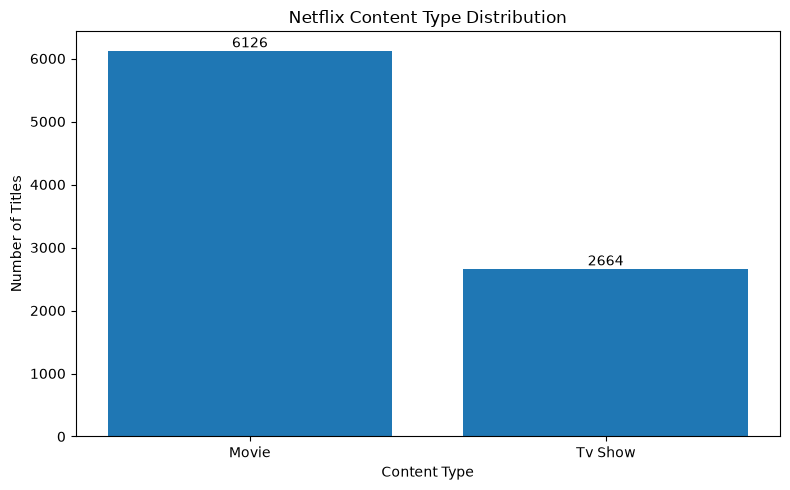

In [192]:
# Create Bar Chart...

plt.figure(figsize=(8,5))
plt.bar(content_type_counts.index, content_type_counts.values)
plt.title("Netflix Content Type Distribution")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
for i, value in enumerate(content_type_counts.values):
    plt.text(i, value, str(value), ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.show()

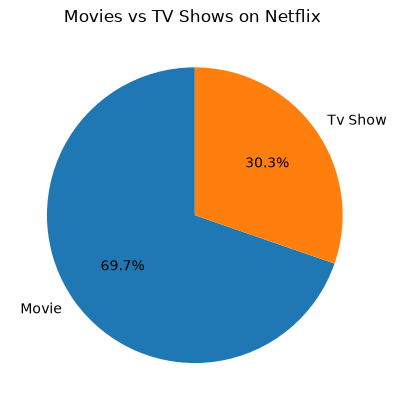

In [193]:
# Create Pie Chart...

plt.Figure(figsize=(7,7))
plt.pie(
    content_type_counts.values,
    labels=content_type_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Movies vs TV Shows on Netflix ")
plt.show()

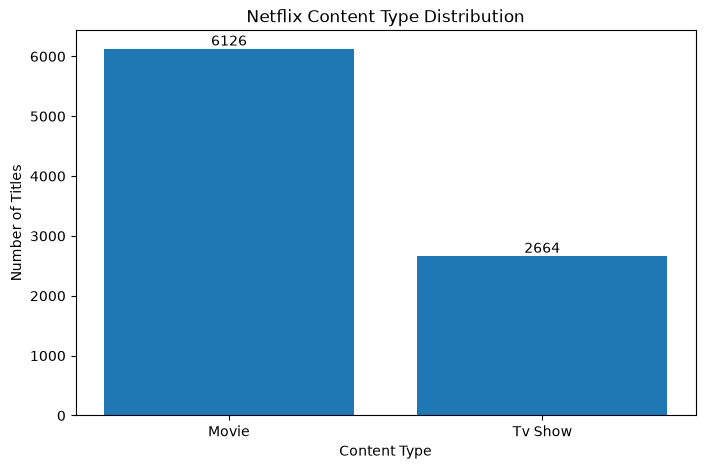

In [194]:
# Save Bar Chart...

plt.figure(figsize=(8, 5))
plt.bar(content_type_counts.index, content_type_counts.values)
plt.title("Netflix Content Type Distribution")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

for i, value in enumerate(content_type_counts.values):
    plt.text(i, value, str(value), ha="center", va="bottom")

plt.savefig("charts/content_type_distribution.png", bbox_inches="tight")
plt.show()

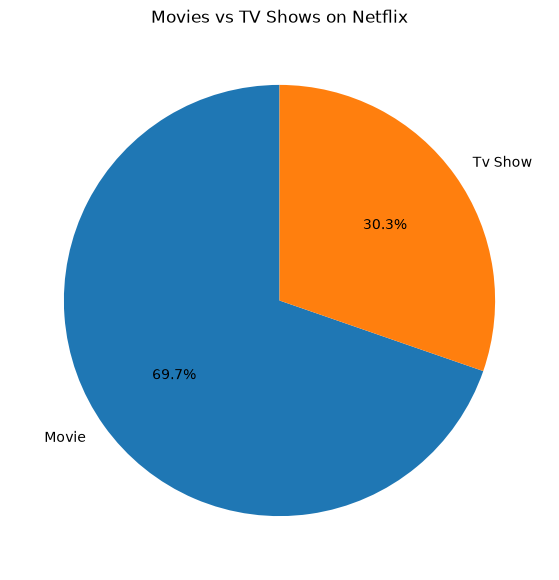

In [195]:
# Save Pie Chart...

plt.figure(figsize=(7, 7))
plt.pie(
    content_type_counts.values,
    labels=content_type_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Movies vs TV Shows on Netflix")
plt.savefig("charts/movies_vs_tv_shows.png", bbox_inches="tight")
plt.show()

In [196]:
# ============================================================
# TASK 3 - COUNTRY-WISE NETFLIX CONTENT ANALYSIS
# ============================================================

In [197]:
cleaned_df["country"].head()

0    United States
1           France
2    United States
3           Brazil
4    United States
Name: country, dtype: str

In [198]:
country_data=cleaned_df[["title", "country"]].copy()

In [199]:
country_data=country_data.dropna(subset=["country"])

In [200]:
country_data["country"] = country_data["country"].str.split(",")

In [201]:
country_data=country_data.explode("country")

In [202]:
country_data["country"]=country_data["country"].str.strip()

In [203]:
country_counts=country_data["country"].value_counts()

In [204]:
top_10_countries = country_counts.head(10)

print("🌍 Top 10 Countries Producing Netflix Content:")
print(top_10_countries)

🌍 Top 10 Countries Producing Netflix Content:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64


In [205]:
import matplotlib.pyplot as plt

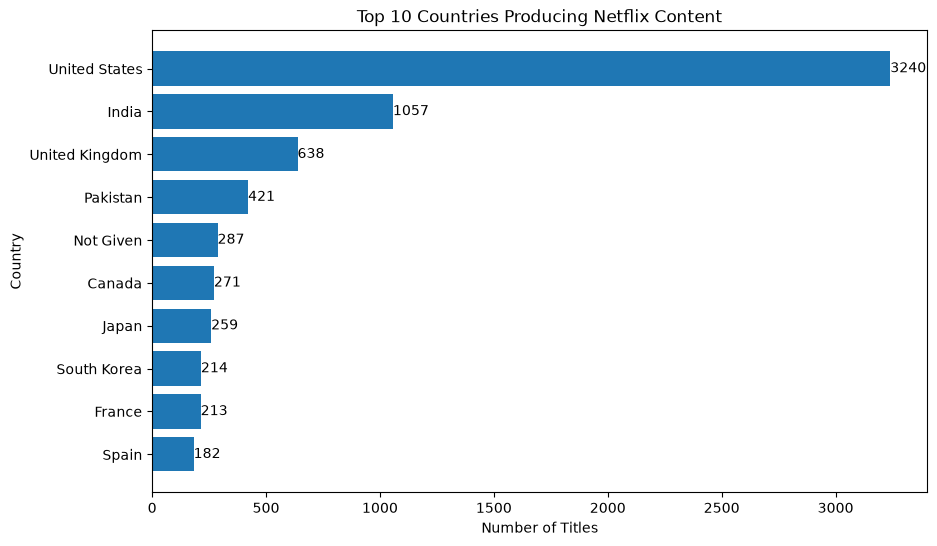

In [206]:
# Create Top 10 Countries chart

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_countries.index[::-1],
    top_10_countries.values[::-1]
)

plt.title("Top 10 Countries Producing Netflix Content")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
for i, value in enumerate(top_10_countries.values[::-1]):
    plt.text(value, i, str(value), va="center")

In [207]:
# Save chart

plt.savefig(
    "charts/top_10_countries.png",
    bbox_inches="tight"
)
plt.show()
print(" Top Content Producing Country:", country_counts.index[0])
print(" Number of Titles:", country_counts.iloc[0])

<Figure size 640x480 with 0 Axes>

 Top Content Producing Country: United States
 Number of Titles: 3240


In [208]:
# ============================================================
# 📈 TASK 4 - TREND ANALYSIS BY RELEASE YEAR
# ============================================================

In [209]:
yearly_content=cleaned_df["release_year"].value_counts().sort_index()

In [210]:
print("Netflix Content By Released Year...")
print(yearly_content)

Netflix Content By Released Year...
release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: count, Length: 74, dtype: int64


In [211]:
import matplotlib.pyplot as plt

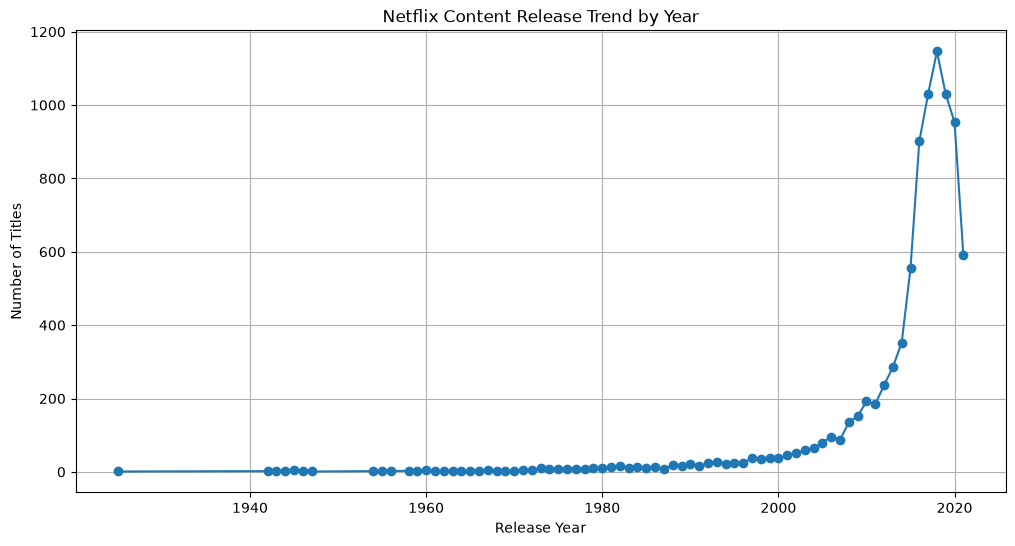

In [212]:
# Trend Chart...

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_content.index,
    yearly_content.values,
    marker="o"
)

plt.title("Netflix Content Release Trend by Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)

In [213]:
# Save trend chart
plt.savefig(
    "charts/release_year_trend.png",
    bbox_inches="tight"
)
plt.show()
highest_year = yearly_content.idxmax()
highest_count = yearly_content.max()
print(" Year with Highest Content:", highest_year)
print(" Number of Titles:", highest_count) 

<Figure size 640x480 with 0 Axes>

 Year with Highest Content: 2018
 Number of Titles: 1146


In [214]:
# ============================================================
#  TASK 5 - CONTENT RATING & GENRE ANALYSIS
# ============================================================

In [215]:
rating_counts=cleaned_df["rating"].value_counts()
print(" Netflix Comtent By rating :")
print(rating_counts)

 Netflix Comtent By rating :
rating
Tv-Ma       3205
Tv-14       2157
Tv-Pg        861
R            799
Pg-13        490
Tv-Y7        333
Tv-Y         306
Pg           287
Tv-G         220
Nr            79
G             41
Tv-Y7-Fv       6
Nc-17          3
Ur             3
Name: count, dtype: int64


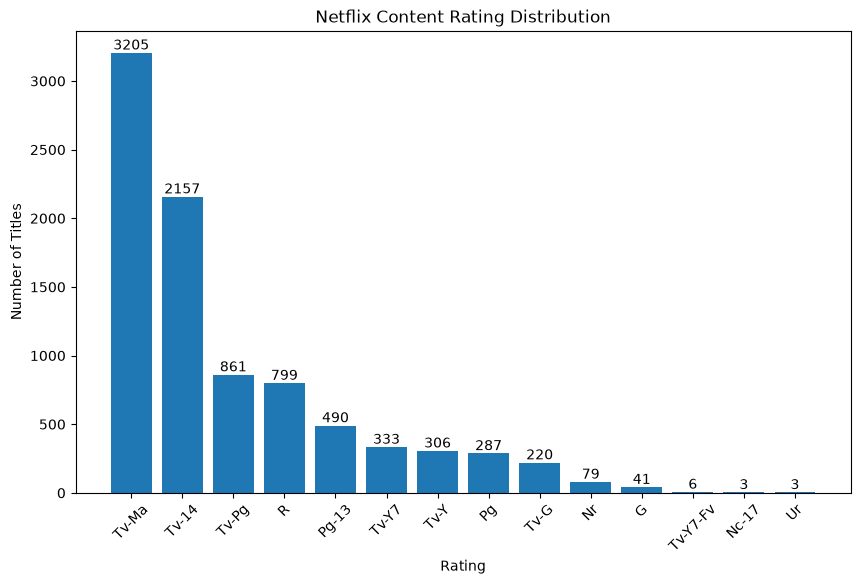

In [216]:
# Plot Rating Distribution...

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.bar(
    rating_counts.index,
    rating_counts.values
)

plt.title("Netflix Content Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
for i, value in enumerate(rating_counts.values):
    plt.text(
        i,
        value,
        str(value),
        ha="center",
        va="bottom"
    )

plt.savefig(
    "charts/content_rating_distribution.png",
    bbox_inches="tight"
)
plt.show()

In [217]:
genre_data=cleaned_df[["title", "listed_in"]].copy()

In [218]:
genre_data=genre_data.dropna(subset=["listed_in"])

In [219]:
genre_data["listed_in"]=genre_data["listed_in"].str.split()

In [220]:
genre_data=genre_data.explode("listed_in")

In [221]:
genre_data["listed_in"]=genre_data["listed_in"].str.strip()

In [222]:
genre_counts=genre_data["listed_in"].value_counts()

In [223]:
top_10_genres=genre_counts.head(10)
print(" Top 10 Netflix Genres :")
print(top_10_genres)

 Top 10 Netflix Genres :
listed_in
TV               5213
International    4101
Movies           3417
&                2607
Shows,           2306
Dramas,          2281
Movies,          2266
Comedies,        1429
Action           1026
Romantic          986
Name: count, dtype: int64


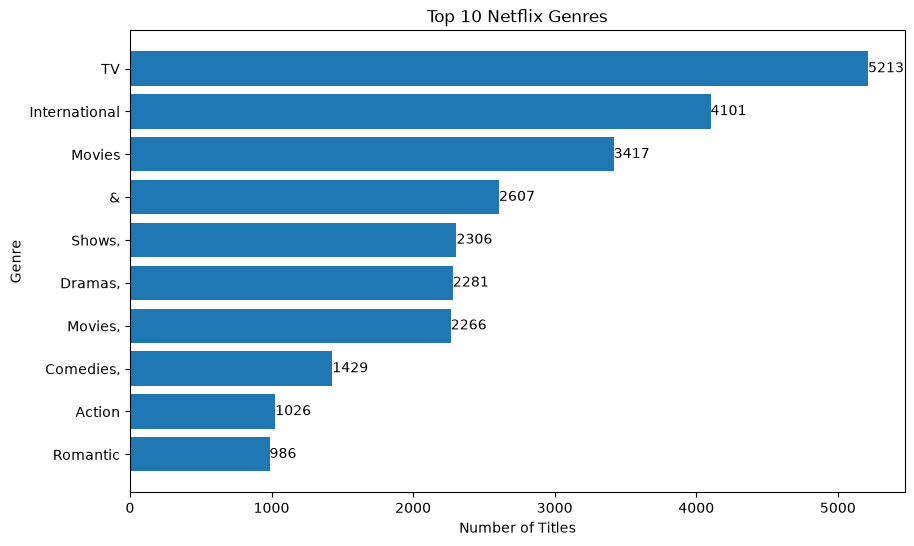

In [224]:
# Genre Chart...

plt.figure(figsize=(10, 6))
plt.barh(
    top_10_genres.index[::-1],
    top_10_genres.values[::-1]
)
plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
for i, value in enumerate(top_10_genres.values[::-1]):
    plt.text(
        value,
        i,
        str(value),
        va="center"
    )

plt.savefig(
    "charts/top_10_genres.png",
    bbox_inches="tight"
)

plt.show()

In [225]:
rating_type = pd.crosstab(
    cleaned_df["rating"],
    cleaned_df["type"]
)

print("📊 Rating Comparison by Content Type:")
print(rating_type)

📊 Rating Comparison by Content Type:
type      Movie  Tv Show
rating                  
G            41        0
Nc-17         3        0
Nr           75        4
Pg          287        0
Pg-13       490        0
R           797        2
Tv-14      1427      730
Tv-G        126       94
Tv-Ma      2062     1143
Tv-Pg       540      321
Tv-Y        131      175
Tv-Y7       139      194
Tv-Y7-Fv      5        1
Ur            3        0


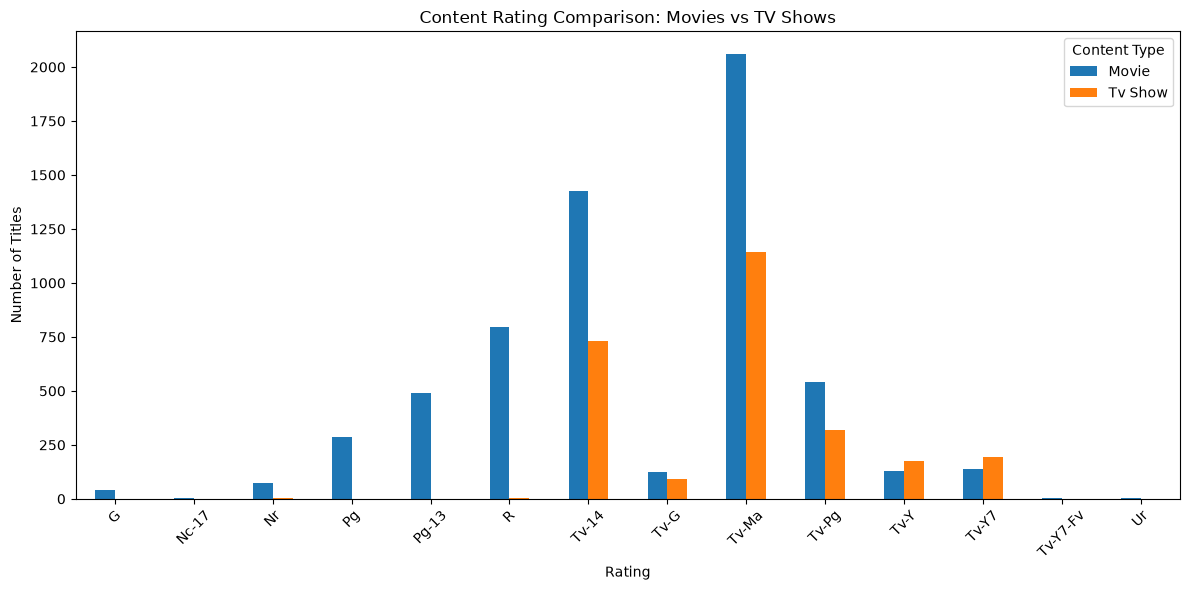

In [226]:
# Comparison Chart..

rating_type.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Content Rating Comparison: Movies vs TV Shows")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.legend(title="Content Type")
plt.tight_layout()
plt.savefig(
    "charts/rating_comparison.png",
    bbox_inches="tight"
)

plt.show()

In [227]:
# ============================================================
# 💼 TASK 6 - NETFLIX BUSINESS INSIGHTS REPORT
# ============================================================

In [228]:
total_titles=len(cleaned_df)
total_movies=(cleaned_df["type"] == "Movie").sum()
total_tv_shows=(cleaned_df["type"] == "TV Show").sum()

print(" NETFLIX BUSSINESS INSIGHTS REPORTS..")
print("=" * 50)

print("Total Netflix Titles : ", total_titles)
print("Total Movies :", total_movies)
print("Total TV Shows :", total_tv_shows)

 NETFLIX BUSSINESS INSIGHTS REPORTS..
Total Netflix Titles :  8790
Total Movies : 6126
Total TV Shows : 0


In [229]:
most_common_type = cleaned_df["type"].value_counts().idxmax()
print("Most Common Content Type:", most_common_type)

Most Common Content Type: Movie


In [230]:
most_common_rating = cleaned_df["rating"].value_counts().idxmax()
print("Most Common Rating:", most_common_rating)

Most Common Rating: Tv-Ma


In [231]:
most_common_genre = genre_counts.idxmax()
print("Most Common Genre:", most_common_genre)

Most Common Genre: TV


In [232]:
top_country = country_counts.idxmax()
print("Top Content Producing Country:", top_country)

Top Content Producing Country: United States


In [233]:
peak_year = yearly_content.idxmax()
print("Peak Release Year:", peak_year)

Peak Release Year: 2018


In [234]:
insights = {
    "Total Titles": total_titles,
    "Total Movies": total_movies,
    "Total TV Shows": total_tv_shows,
    "Most Common Content Type": most_common_type,
    "Most Common Rating": most_common_rating,
    "Most Common Genre": most_common_genre,
    "Top Producing Country": top_country,
    "Peak Release Year": peak_year
}

In [235]:
insights_df = pd.DataFrame(
    list(insights.items()),
    columns=["Insight", "Value"]
)

In [236]:
print("\n KEY BUSINESS INSIGHTS")
print("=" * 50)

print(insights_df)


 KEY BUSINESS INSIGHTS
                    Insight          Value
0              Total Titles           8790
1              Total Movies           6126
2            Total TV Shows              0
3  Most Common Content Type          Movie
4        Most Common Rating          Tv-Ma
5         Most Common Genre             TV
6     Top Producing Country  United States
7         Peak Release Year           2018


In [237]:
insights_df.to_csv(
    "report/netflix_business_insights.csv",
    index=False
)

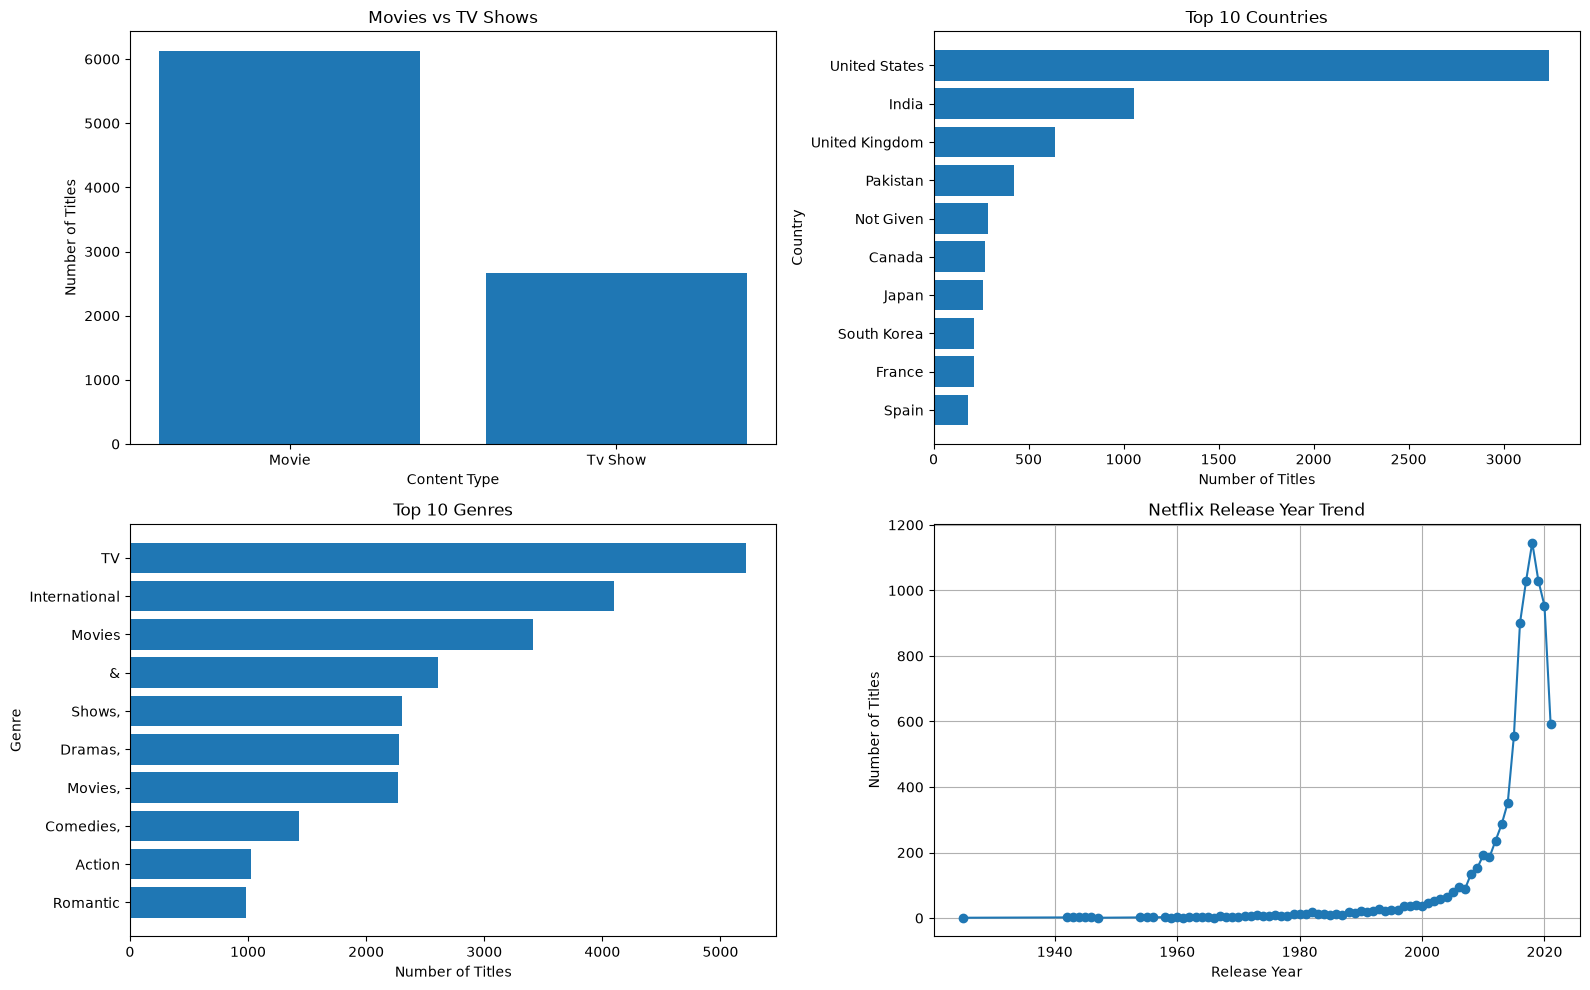

In [238]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1️ Movies vs TV Shows
axes[0, 0].bar(
    content_type_counts.index,
    content_type_counts.values
)

axes[0, 0].set_title("Movies vs TV Shows")
axes[0, 0].set_xlabel("Content Type")
axes[0, 0].set_ylabel("Number of Titles")

# 2️ Top 10 Countries
axes[0, 1].barh(
    top_10_countries.index[::-1],
    top_10_countries.values[::-1]
)

axes[0, 1].set_title("Top 10 Countries")
axes[0, 1].set_xlabel("Number of Titles")
axes[0, 1].set_ylabel("Country")

# 3️ Top 10 Genres
axes[1, 0].barh(
    top_10_genres.index[::-1],
    top_10_genres.values[::-1]
)

axes[1, 0].set_title("Top 10 Genres")
axes[1, 0].set_xlabel("Number of Titles")
axes[1, 0].set_ylabel("Genre")

# 4️ Release Year Trend
axes[1, 1].plot(
    yearly_content.index,
    yearly_content.values,
    marker="o"
)

axes[1, 1].set_title("Netflix Release Year Trend")
axes[1, 1].set_xlabel("Release Year")
axes[1, 1].set_ylabel("Number of Titles")

axes[1, 1].grid(True)

# Adjust layout
plt.tight_layout()

# Save dashboard
plt.savefig(
    "charts/final_netflix_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

# Show dashboard
plt.show()